# Case Control Study Audit

How are sampled cancer cases distributed by alcohol group?

Data: [datasets/esoph](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/esoph.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Case counts are sampled study counts, not population cancer incidence or risk; age and tobacco confound comparisons.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Case Control Study Audit',
 'executed_utc': '2026-11-21T10:14:13.481678+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/esoph.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/esoph.html',
 'sha256': '140e94cc9beca332888a19eddcb99fabccb380cf1862d025641643a4cae6349d',
 'raw_rows': 88,
 'analysis_rows': 88,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,88
1,agegp,object,0,0.0,6
2,alcgp,object,0,0.0,4
3,tobgp,object,0,0.0,4
4,ncases,int64,0,0.0,10
5,ncontrols,int64,0,0.0,27


## SQL and analysis
Sum recorded ncases within each alcgp category; the row grain is an aggregated cell.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "alcgp" AS segment, COUNT(*) AS rows_used, SUM("ncases") AS metric, MIN("ncases") AS minimum, MAX("ncases") AS maximum FROM observations GROUP BY "alcgp" ORDER BY "alcgp";

The largest observed sum of ncases is 75.000 for 40-79. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,0-39g/day,23,29,0,5
1,120+,21,45,0,6
2,40-79,23,75,0,17
3,80-119,21,51,0,9


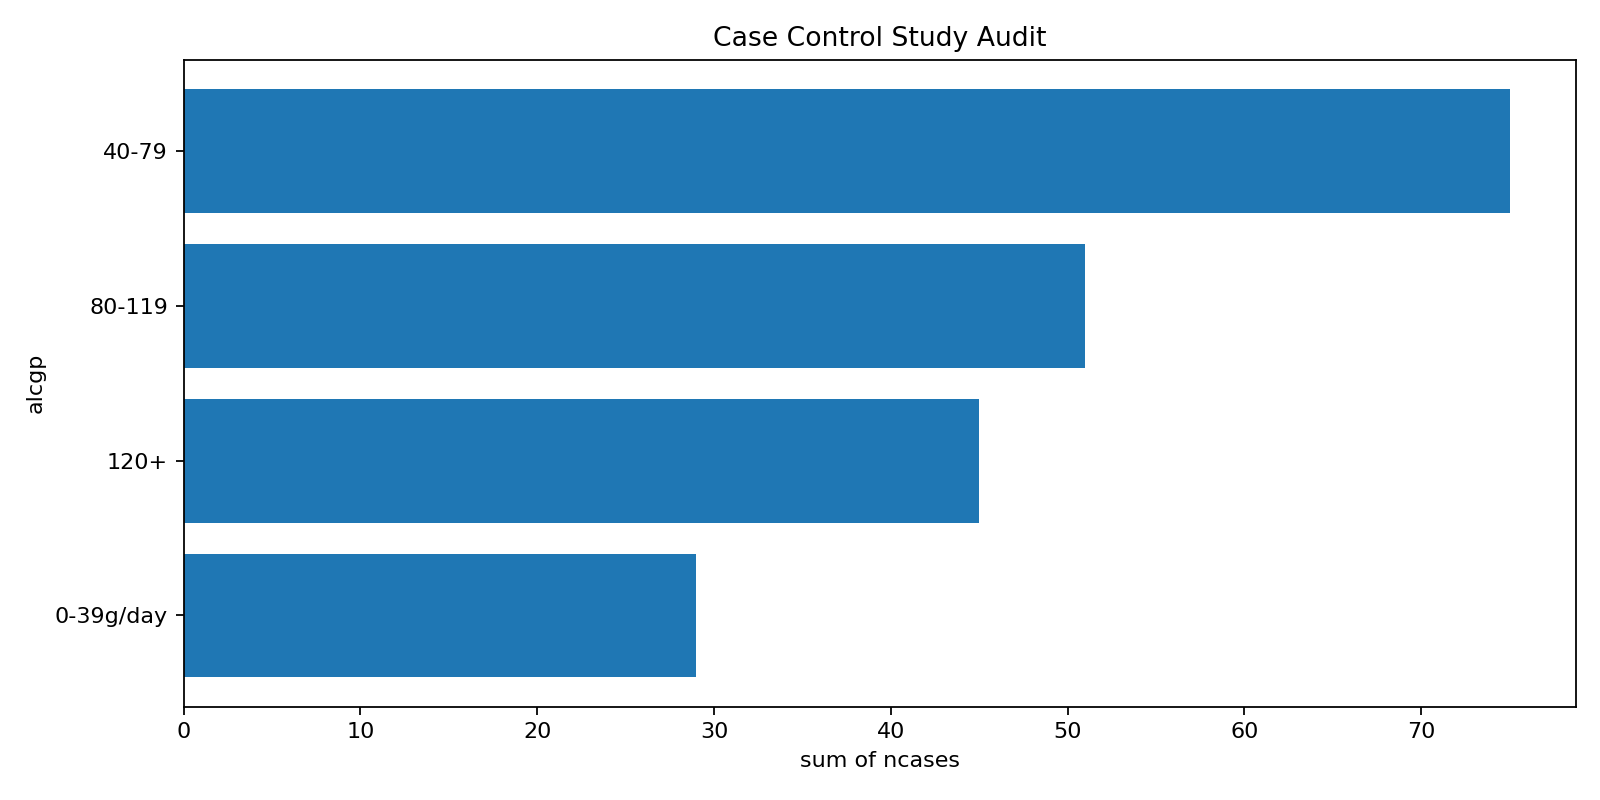

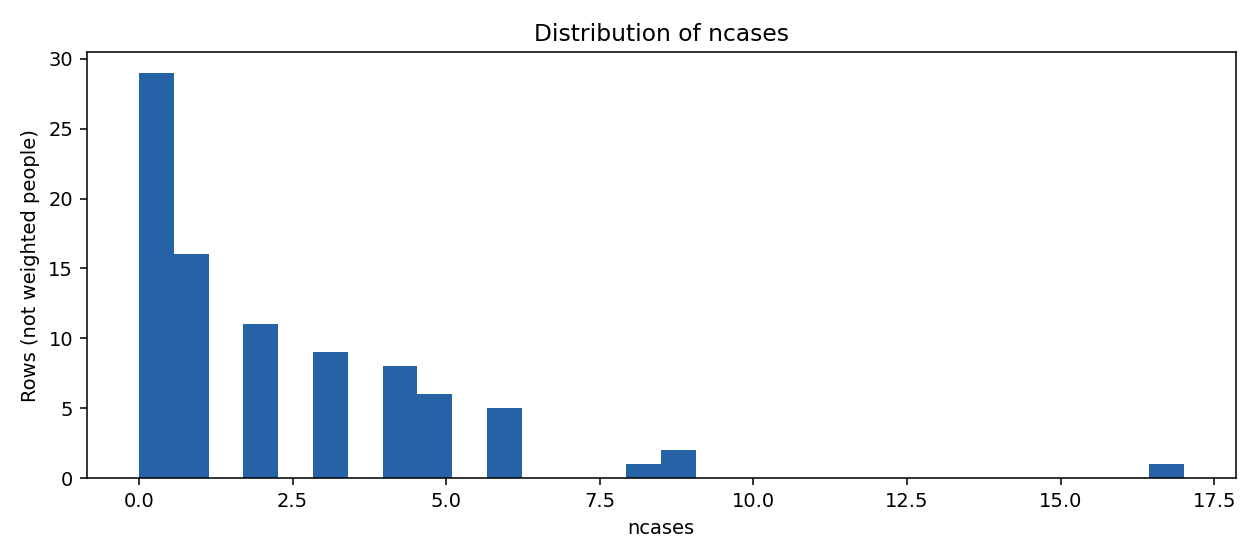

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Case counts are sampled study counts, not population cancer incidence or risk; age and tobacco confound comparisons.

**Next action:** Use appropriate case-control odds models with adjustment for age and tobacco.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.